# Home assignment 2: IMU gesture recognition, model building and optimization

Markkus Koddala, 253101IAPM. IAS0360 Machine Learning for Embedded Systems, 2026.

Built on Lab 2.2 IMU (`lab_2_2/imu/magic_wand_cnn.ipynb`). One section per
HW2 step:

| Step | Task | Section |
|---|---|---|
| 1 | Gesture recognition on the Lab 2.2 dataset, own architecture | Step 1 |
| 2 | Own data from the Pico, converted to the training format | Step 2 |
| 3 | Choose one optimization category | Step 3 |
| 4 | Optimize toward it (training parameters, architecture) | Step 4 |
| 5 | Results table | Step 5 |
| 6 | Two other architectures, three in total | Step 6 |

Data:
- `data/shared/<class>/`: Lab 2.2 dataset, used for train / validation / test.
- `data/own/<class>/`: own Pico recordings, used **only** for the
  "own data accuracy" column, never for training.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

HW2_DIR = Path.cwd()
sys.path.insert(0, str(HW2_DIR / "src"))
from preprocessor import (prepare_dataset, load_prepared_dataset, load_csv,
                          preprocess_recording, normalize, CLASS_NAMES,
                          SAMPLING_RATE_HZ)

DATA_DIR = HW2_DIR / "data"
MODEL_DIR = HW2_DIR / "models"
FIG_DIR = HW2_DIR / "report" / "figs"
MODEL_DIR.mkdir(exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEQ_LEN = 128      # samples per gesture after resampling
N_SEEDS = 3        # every configuration is trained this many times; mean +/- std is reported

print("TensorFlow", tf.__version__)

I0000 00:00:1793817803.456691 1938026 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793817803.457150 1938026 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793817803.497236 1938026 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793817804.380845 1938026 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793817804.381151 1938026 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


/home/markkus-24/ias0360/.venv/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


TensorFlow 2.21.0


## Step 1: gesture recognition with an own architecture

Dataset: Lab 2.2 magic wand data, 4 classes (negative, ring, slope, wing),
25 recordings each. `prepare_dataset()` converts counts to g, low-pass filters
at 20 Hz, resamples each recording to 128 samples, splits 60/20/20 **by
recording** (stratified) and normalises with training-set statistics only.

In [2]:
SHARED_NPZ = DATA_DIR / "shared_dataset.npz"
prepare_dataset(dataset_dir=DATA_DIR / "shared", output_path=SHARED_NPZ,
                target_length=SEQ_LEN)
dataset = load_prepared_dataset(SHARED_NPZ)
CLASSES = dataset["class_names"]
NUM_CLASSES = len(CLASSES)

X_train, y_train = dataset["train"]
X_val, y_val = dataset["validation"]
X_test, y_test = dataset["test"]
# Conv2D input: (time, 3) -> (time, 3, 1)
X_train, X_val, X_test = (x[..., np.newaxis] for x in (X_train, X_val, X_test))
INPUT_SHAPE = X_train.shape[1:]

print("train", X_train.shape, " val", X_val.shape, " test", X_test.shape)
print("classes", CLASSES)

negative: 25 recordings
ring: 25 recordings
slope: 25 recordings
wing: 25 recordings


Class mapping: {0: 'negative', 1: 'ring', 2: 'slope', 3: 'wing'}
train: X=(60, 128, 3), y=(60,), per class={'negative': 15, 'ring': 15, 'slope': 15, 'wing': 15}
validation: X=(20, 128, 3), y=(20,), per class={'negative': 5, 'ring': 5, 'slope': 5, 'wing': 5}
test: X=(20, 128, 3), y=(20,), per class={'negative': 5, 'ring': 5, 'slope': 5, 'wing': 5}
Saved dataset to /home/markkus-24/ias0360/lab-exercises/hw2/data/shared_dataset.npz
train (60, 128, 3, 1)  val (20, 128, 3, 1)  test (20, 128, 3, 1)
classes ['negative', 'ring', 'slope', 'wing']


### Architectures

**Initial model** (`build_baseline`): the Lab 2.2 / lecture slide 64 CNN.
Two Conv2D + MaxPool blocks, Flatten, Dense(16), softmax.
About 85 % of its weights sit in the Flatten -> Dense(16) layer.

**Own model** (`build_own`): same two convolution blocks, but Flatten +
Dense(16) is replaced by **GlobalAveragePooling** straight into the softmax
layer. Each of the 16 feature maps is averaged over time, so the classifier
sees 16 numbers instead of 240. This removes the largest layer and fits the
memory goal (Step 3).

In [3]:
L = tf.keras.layers

def build_baseline(num_filters1=8, num_filters2=16, dense_units=16,
                   activation="relu", dropout=0.1):
    """Lab 2.2 / lecture 08 slide 64 architecture (initial model)."""
    return tf.keras.Sequential([
        L.Input(shape=INPUT_SHAPE),
        L.Conv2D(num_filters1, (4, 3), padding="same", activation=activation),
        L.MaxPooling2D((3, 3), strides=(3, 3), padding="same"),
        L.Conv2D(num_filters2, (4, 1), padding="same", activation=activation),
        L.MaxPooling2D((3, 1), strides=(3, 1), padding="same"),
        L.Flatten(),
        L.Dropout(dropout),
        L.Dense(dense_units, activation=activation),
        L.Dropout(dropout),
        L.Dense(NUM_CLASSES, activation="softmax"),
    ], name="baseline")


def build_own(num_filters1=8, num_filters2=16, activation="relu", dropout=0.1):
    """Own architecture: conv blocks + global average pooling, no hidden Dense."""
    return tf.keras.Sequential([
        L.Input(shape=INPUT_SHAPE),
        L.Conv2D(num_filters1, (4, 3), padding="same", activation=activation),
        L.MaxPooling2D((3, 3), strides=(3, 3), padding="same"),
        L.Conv2D(num_filters2, (4, 1), padding="same", activation=activation),
        L.MaxPooling2D((3, 1), strides=(3, 1), padding="same"),
        L.GlobalAveragePooling2D(),
        L.Dropout(dropout),
        L.Dense(NUM_CLASSES, activation="softmax"),
    ], name="own_gap")


build_baseline().summary()
build_own().summary()

E0000 00:00:1793817807.224832 1938026 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793817807.225156 1938735 cuda_executor.cc:1755] Failed to determine cuDNN version (Note that this is expected if the application doesn't link the cuDNN plugin): INTERNAL: cuDNN error: CUDNN_STATUS_INTERNAL_ERROR
W0000 00:00:1793817807.245973 1938026 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 3, 8)      │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 43, 1, 8)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 43, 1, 16)      │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 15, 1, 16)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 240)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 240)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         3,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,556 (17.80 KB)

 Trainable params: 4,556 (17.80 KB)

 Non-trainable params: 0 (0.00 B)

Model: "own_gap"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 128, 3, 8)      │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 43, 1, 8)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 43, 1, 16)      │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 15, 1, 16)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 16)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 700 (2.73 KB)

 Trainable params: 700 (2.73 KB)

 Non-trainable params: 0 (0.00 B)

### Training and evaluation helpers

`train_model` trains one configuration with a fixed seed.
`evaluate_config` repeats it for `N_SEEDS` seeds, because validation and test
sets have only 20 gestures each: one gesture is 5 % of accuracy, and a single
run mostly measures the random initialisation.

In [4]:
def make_optimizer(name, lr):
    return {"adam": tf.keras.optimizers.Adam,
            "sgd": lambda lr: tf.keras.optimizers.SGD(lr, momentum=0.9),
            "rmsprop": tf.keras.optimizers.RMSprop}[name](lr)


def train_model(build_fn, seed, epochs=30, batch_size=16, optimizer="adam",
                lr=1e-3, **arch_kwargs):
    tf.keras.utils.set_random_seed(seed)
    model = build_fn(**arch_kwargs)
    model.compile(optimizer=make_optimizer(optimizer, lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    history = model.fit(X_train, y_train, epochs=epochs, batch_size=batch_size,
                        validation_data=(X_val, y_val), verbose=0)
    return model, history

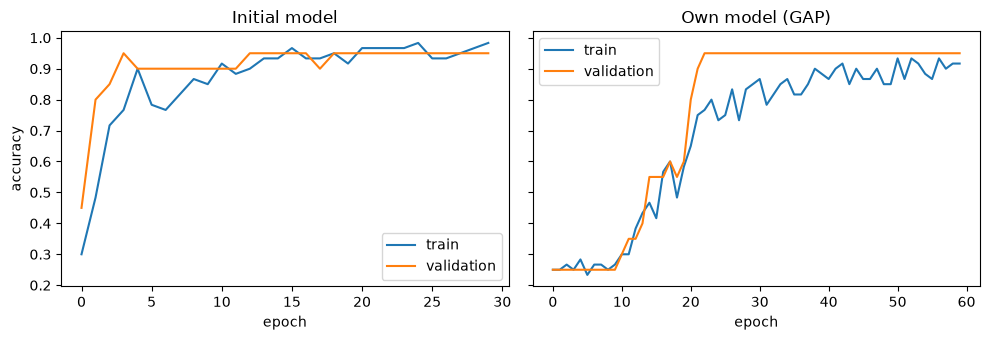

initial: test accuracy 0.950, params 4556
own: test accuracy 1.000, params 700


In [5]:
baseline_model, baseline_hist = train_model(build_baseline, seed=0)
own_model, own_hist = train_model(build_own, seed=0, epochs=60)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, (name, h) in zip(axes, [("Initial model", baseline_hist),
                                ("Own model (GAP)", own_hist)]):
    ax.plot(h.history["accuracy"], label="train")
    ax.plot(h.history["val_accuracy"], label="validation")
    ax.set_title(name); ax.set_xlabel("epoch"); ax.legend()
axes[0].set_ylabel("accuracy")
plt.tight_layout()
plt.savefig(FIG_DIR / "step1_training_curves.png", dpi=150)
plt.show()

for name, m in [("initial", baseline_model), ("own", own_model)]:
    _, acc = m.evaluate(X_test, y_test, verbose=0)
    print(f"{name}: test accuracy {acc:.3f}, params {m.count_params()}")

## Step 2: own data from the Pico

No SD card was available, so own data was recorded with `data_collection_serial/`
(same accelerometer data as the lab's `data_collection/`, fixed 2000 Hz, 2.1 s =
4200 rows, sent over USB serial) and `tools/record_serial.py`, which writes
`data/own/<class>/own_<time>.txt`. 5 recordings per class, 20 in total.

The shared set was recorded with the board screen **down** (gravity on +z). Own
recordings were made with the board held **upright**, gravity on -x, gestures
drawn in the board's x-y plane. `ROTATION` maps own-recording axes to shared axes
(`shared = ROTATION @ own`) before the usual preprocessing.


In [6]:
# Own recordings: board held upright, gravity on -x. Shared set: gravity on +z.
# Gestures were drawn in the own x-y plane. Map own axes to shared axes:
#   shared_x = +own_z,  shared_y = +own_y,  shared_z = -own_x
# This matches the physical layout, and it scored best of all 24 axis
# rotations on the own data.
ROTATION = np.array([[0, 0, 1],
                     [0, 1, 0],
                     [-1, 0, 0]], dtype=float)


def load_own_data(own_dir=DATA_DIR / "own"):
    X, y = [], []
    for label, cls in enumerate(CLASSES):
        for path in sorted((own_dir / cls).glob("*.txt")):
            raw = load_csv(path)
            X.append(preprocess_recording(raw, sample_rate_hz=SAMPLING_RATE_HZ,
                                          target_length=SEQ_LEN, rotation=ROTATION))
            y.append(label)
    X = normalize(np.stack(X), dataset)[..., np.newaxis]
    return X, np.array(y)


X_own, y_own = load_own_data()
print(len(y_own), "own gestures:", {c: int((y_own == i).sum()) for i, c in enumerate(CLASSES)})

20 own gestures: {'negative': 5, 'ring': 5, 'slope': 5, 'wing': 5}


## Step 3: optimization category

**Chosen: memory size (weights + model).**

The target is a Pico W with 264 KB SRAM and 2 MB flash, shared with the IMU
driver, USB stack and the TFLite Micro tensor arena. The baseline is already
accurate on the shared data, so accuracy leaves little to show, and on a
microcontroller a smaller model is usually also faster.

Memory is reported as:
- trainable parameters (`model.summary()`), as the assignment asks,
- weight size: parameters x 4 bytes (float32) or x 1 byte (int8),
- size of the `.tflite` file, the model as it would be flashed to the Pico.

In [7]:
OPT_GOAL = "memory"   # one of: "speed", "memory", "accuracy"

## Step 4: optimization experiments

Each configuration is trained `N_SEEDS` times. Every trained model is
converted to TFLite (float32, or int8 with post-training quantization), and
all numbers come from the TFLite model, because that is what runs on the Pico:

- **inference ms**: total prediction time on the own data divided by the
  number of own gestures, one gesture at a time, on the PC,
- **params**, **weights KB**, **tflite KB**: memory,
- **val / test / own acc**: mean over seeds (val std shows the spread).

The second row is the example from the assignment text (10 epochs,
learning rate 0.05). The last rows add int8 quantization (Lab 2.3).

In [8]:
def to_tflite(model, int8=False):
    """Convert to TFLite. int8=True: full-integer post-training quantization."""
    converter = tf.lite.TFLiteConverter.from_keras_model(model)
    if int8:
        def representative_data():
            for x in X_train:
                yield [x[np.newaxis].astype(np.float32)]
        converter.optimizations = [tf.lite.Optimize.DEFAULT]
        converter.representative_dataset = representative_data
        converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        converter.inference_input_type = tf.int8
        converter.inference_output_type = tf.int8
    return converter.convert()


def run_tflite(tflite_model, X):
    """Predict one gesture at a time. Returns predicted classes and ms per gesture."""
    interpreter = tf.lite.Interpreter(model_content=tflite_model)
    interpreter.allocate_tensors()
    inp = interpreter.get_input_details()[0]
    out = interpreter.get_output_details()[0]
    scale, zero_point = inp["quantization"]

    preds = []
    start = time.perf_counter()
    for x in X:
        x = x[np.newaxis].astype(np.float32)
        if inp["dtype"] == np.int8:
            x = np.clip(np.round(x / scale + zero_point), -128, 127).astype(np.int8)
        interpreter.set_tensor(inp["index"], x)
        interpreter.invoke()
        preds.append(interpreter.get_tensor(out["index"])[0].argmax())
    ms = (time.perf_counter() - start) / len(X) * 1000
    return np.array(preds), ms


def evaluate_config(name, build_fn, int8=False, **cfg):
    runs = []
    for seed in range(N_SEEDS):
        model, _ = train_model(build_fn, seed=seed, **cfg)
        tflite_model = to_tflite(model, int8)
        val_pred, _ = run_tflite(tflite_model, X_val)
        test_pred, _ = run_tflite(tflite_model, X_test)
        own_pred, ms = run_tflite(tflite_model, X_own)
        runs.append(dict(val=np.mean(val_pred == y_val), test=np.mean(test_pred == y_test),
                         own=np.mean(own_pred == y_own), ms=ms))
    r = pd.DataFrame(runs)
    params = model.count_params()
    row = {
        "optimization method": name,
        "inference ms": r.ms.mean(),
        "params": params,
        "weights KB": params * (1 if int8 else 4) / 1024,
        "tflite KB": len(tflite_model) / 1024,
        "val acc": r.val.mean(), "val std": r.val.std(),
        "test acc": r.test.mean(),
        "own acc": r.own.mean(),
    }
    return row, model

In [9]:
EXPERIMENTS = [
    # name, build function, config
    ("Initial model (lab baseline)",       build_baseline, {}),
    ("Initial, epochs=10, lr=0.05",        build_baseline, dict(epochs=10, lr=0.05)),
    ("Initial, lr=1e-2",                   build_baseline, dict(lr=1e-2)),
    ("Initial, SGD momentum 0.9, lr=1e-2", build_baseline, dict(optimizer="sgd", lr=1e-2)),
    ("Initial, RMSprop",                   build_baseline, dict(optimizer="rmsprop")),
    ("Initial, batch 32",                  build_baseline, dict(batch_size=32)),
    ("Initial, tanh",                      build_baseline, dict(activation="tanh")),
    ("Initial, dropout 0.3",               build_baseline, dict(dropout=0.3)),
    ("Initial, filters 4/8, dense 8",      build_baseline, dict(num_filters1=4, num_filters2=8, dense_units=8)),
    ("Own: GAP head",                      build_own, dict(epochs=60)),
    ("Own: GAP head, lr=1e-2",             build_own, dict(epochs=60, lr=1e-2)),
    ("Own: GAP head, filters 4/8",         build_own, dict(epochs=60, num_filters1=4, num_filters2=8)),
    ("Own: GAP head, filters 4/8, lr=1e-2", build_own, dict(epochs=60, lr=1e-2, num_filters1=4, num_filters2=8)),
    # int8 post-training quantization
    ("Initial model + int8",               build_baseline, dict(int8=True)),
    ("Own: GAP head, lr=1e-2 + int8",      build_own, dict(epochs=60, lr=1e-2, int8=True)),
    ("Own: GAP head, filters 4/8, lr=1e-2 + int8", build_own, dict(epochs=60, lr=1e-2, num_filters1=4, num_filters2=8, int8=True)),
]

results, trained = [], {}
for name, fn, cfg in EXPERIMENTS:
    row, model = evaluate_config(name, fn, **cfg)
    results.append(row)
    trained[name] = model
    print(f"{name:45s} val {row['val acc']:.2f}  own {row['own acc']:.2f}  tflite {row['tflite KB']:.1f} KB")

INFO:tensorflow:Assets written to: /tmp/tmpd630n1gs/assets


INFO:tensorflow:Assets written to: /tmp/tmpd630n1gs/assets


Saved artifact at '/tmp/tmpd630n1gs'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 3, 1), dtype=tf.float32, name='keras_tensor_36')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  136547284453904: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136547284455440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136547284456400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136547284455248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136547284453712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136547284456016: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136547284453136: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136547284452752: TensorSpec(shape=(), dtype=tf.resource, name=None)


W0000 00:00:1793817817.327033 1938026 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793817817.327045 1938026 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793817817.327243 1938026 reader.cc:83] Reading SavedModel from: /tmp/tmpd630n1gs
I0000 00:00:1793817817.327673 1938026 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793817817.327677 1938026 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpd630n1gs
I0000 00:00:1793817817.331296 1938026 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled
I0000 00:00:1793817817.331870 1938026 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1793817817.353990 1938026 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpd630n1gs
I0000 00:00:1793817817.359867 1938026 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 32629 microseconds.
I0000 00:00:1793817817.367568 1938026

INFO:tensorflow:Assets written to: /tmp/tmpunh5h337/assets


INFO:tensorflow:Assets written to: /tmp/tmpunh5h337/assets


... (198 outputs left out)

INFO:tensorflow:Assets written to: /tmp/tmp0jqmy_aw/assets


Saved artifact at '/tmp/tmp0jqmy_aw'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 3, 1), dtype=tf.float32, name='keras_tensor_472')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  136543194989200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136543194997072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136543194999952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136543195004560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136543194999184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136543194998416: TensorSpec(shape=(), dtype=tf.resource, name=None)


Own: GAP head, filters 4/8, lr=1e-2 + int8    val 0.97  own 0.48  tflite 4.3 KB


/home/markkus-24/ias0360/.venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793817975.080595 1938026 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793817975.080607 1938026 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793817975.080733 1938026 reader.cc:83] Reading SavedModel from: /tmp/tmp0jqmy_aw
I0000 00:00:1793817975.081027 1938026 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793817975.081031 1938026 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp0jqmy_aw
I0000 00:00:1793817975.083360 1938026 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1793817975.098218 1938026 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp0jqmy_aw
I0000 00:00:1793817975.102723 1938026 loader.cc:471] SavedModel load for t

## Step 5: results table

Same columns as the assignment table. Accuracies are means over `N_SEEDS`
runs. Saved to `report/results_table.csv` for the report.

In [10]:
def show_table(rows):
    return pd.DataFrame(rows).round({"inference ms": 3, "weights KB": 2, "tflite KB": 1,
                                     "val acc": 3, "val std": 3, "test acc": 3, "own acc": 3})

table = show_table(results)
table.to_csv(HW2_DIR / "report" / "results_table.csv", index=False)
table

,optimization method,inference ms,params,weights KB,tflite KB,val acc,val std,test acc,own acc
0,Initial model (lab baseline),0.008,4556,17.80,22.1,0.950,0.000,0.950,0.400
1,"Initial, epochs=10, lr=0.05",0.008,4556,17.80,22.1,0.933,0.029,0.967,0.150
2,"Initial, lr=1e-2",0.007,4556,17.80,22.1,0.950,0.000,0.950,0.367
3,"Initial, SGD momentum 0.9, lr=1e-2",0.008,4556,17.80,22.1,0.950,0.000,0.950,0.450
4,"Initial, RMSprop",0.008,4556,17.80,22.1,0.950,0.000,0.950,0.433
5,"Initial, batch 32",0.010,4556,17.80,22.1,0.950,0.000,0.950,0.317
6,"Initial, tanh",0.008,4556,17.80,22.4,0.950,0.000,0.950,0.467
7,"Initial, dropout 0.3",0.008,4556,17.80,22.1,0.950,0.000,0.950,0.267
8,"Initial, filters 4/8, dense 8",0.007,1192,4.66,8.9,0.850,0.132,0.883,0.267
9,Own: GAP head,0.007,700,2.73,5.9,0.950,0.000,1.000,0.533


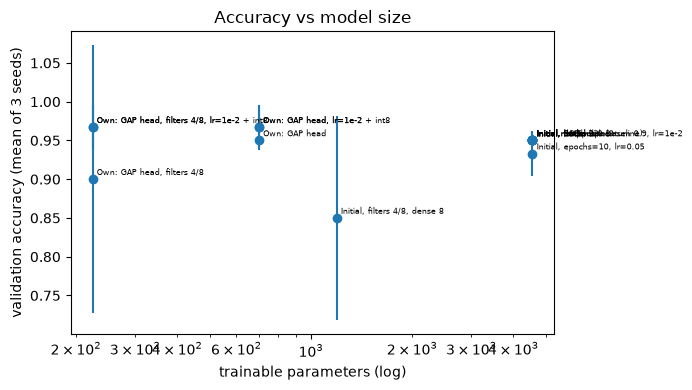

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(table["params"], table["val acc"], yerr=table["val std"], fmt="o")
for _, r in table.iterrows():
    ax.annotate(r["optimization method"], (r["params"], r["val acc"]),
                fontsize=6, xytext=(3, 3), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("trainable parameters (log)")
ax.set_ylabel(f"validation accuracy (mean of {N_SEEDS} seeds)")
ax.set_title("Accuracy vs model size")
plt.tight_layout()
plt.savefig(FIG_DIR / "step5_accuracy_vs_params.png", dpi=150)
plt.show()

## Step 6: two other architectures

Three architectures in total, compared on the same data and metrics:

1. **Own CNN** with global average pooling (Step 1).
2. **MobileNet-style**: a standard conv stem followed by depthwise-separable
   blocks (depthwise conv + 1x1 pointwise conv), the building block of
   MobileNet. Depthwise separable convs need far fewer multiplies than a full
   convolution with the same output size.
3. **SqueezeNet-style**: Fire modules (1x1 "squeeze" conv to few channels,
   then parallel 1x1 and 4x1 "expand" convs, concatenated), the building
   block of SqueezeNet.

The full ImageNet MobileNet / SqueezeNet are far too large for 128x3 IMU
input and for the Pico, so both are scaled-down versions built from the same
blocks. All layers used (Conv2D, DepthwiseConv2D, MaxPool, Concatenate,
GlobalAveragePooling, Dense) have TFLite Micro kernels.

In [12]:
def build_mobilenet_style(stem=8, widths=(16, 32), activation="relu", dropout=0.1):
    x = inp = L.Input(shape=INPUT_SHAPE)
    x = L.Conv2D(stem, (4, 3), padding="valid", activation=activation)(x)   # -> (125, 1, stem)
    for w in widths:
        x = L.DepthwiseConv2D((4, 1), strides=(2, 1), padding="same", activation=activation)(x)
        x = L.Conv2D(w, (1, 1), activation=activation)(x)
    x = L.GlobalAveragePooling2D()(x)
    x = L.Dropout(dropout)(x)
    out = L.Dense(NUM_CLASSES, activation="softmax")(x)
    return tf.keras.Model(inp, out, name="mobilenet_style")


def fire(x, squeeze, expand, activation):
    s = L.Conv2D(squeeze, (1, 1), activation=activation)(x)
    e1 = L.Conv2D(expand, (1, 1), activation=activation)(s)
    e3 = L.Conv2D(expand, (4, 1), padding="same", activation=activation)(s)
    return L.Concatenate()([e1, e3])


def build_squeezenet_style(stem=8, activation="relu", dropout=0.1):
    x = inp = L.Input(shape=INPUT_SHAPE)
    x = L.Conv2D(stem, (4, 3), padding="valid", activation=activation)(x)   # -> (125, 1, stem)
    x = L.MaxPooling2D((3, 1), strides=(2, 1))(x)
    x = fire(x, squeeze=4, expand=8, activation=activation)
    x = L.MaxPooling2D((3, 1), strides=(2, 1))(x)
    x = fire(x, squeeze=4, expand=8, activation=activation)
    x = L.GlobalAveragePooling2D()(x)
    x = L.Dropout(dropout)(x)
    out = L.Dense(NUM_CLASSES, activation="softmax")(x)
    return tf.keras.Model(inp, out, name="squeezenet_style")


build_mobilenet_style().summary()
build_squeezenet_style().summary()

Model: "mobilenet_style"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_52 (InputLayer)     │ (None, 128, 3, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_104 (Conv2D)             │ (None, 125, 1, 8)      │           104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d                │ (None, 63, 1, 8)       │            40 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_105 (Conv2D)             │ (None, 63, 1, 16)      │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_1              │ (None, 32, 1, 16)      │            80 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_106 (Conv2D)             │ (None, 32, 1, 32)      │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_20     │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_84 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_84 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,044 (4.08 KB)

 Trainable params: 1,044 (4.08 KB)

 Non-trainable params: 0 (0.00 B)

Model: "squeezenet_style"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_53      │ (None, 128, 3, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_107 (Conv2D) │ (None, 125, 1, 8) │        104 │ input_layer_53[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_104   │ (None, 62, 1, 8)  │          0 │ conv2d_107[0][0]  │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_108 (Conv2D) │ (None, 62, 1, 4)  │         36 │ max_pooling2d_10… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_109 (Conv2D) │ (None, 62, 1, 8)  │         40 │ conv2d_108[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_110 (Conv2D) │ (None, 62, 1, 8)  │        136 │ conv2d_108[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 62, 1, 16) │          0 │ conv2d_109[0][0], │
│ (Concatenate)       │                   │            │ conv2d_110[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_105   │ (None, 30, 1, 16) │          0 │ concatenate[0][0] │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_111 (Conv2D) │ (None, 30, 1, 4)  │         68 │ max_pooling2d_10… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_112 (Conv2D) │ (None, 30, 1, 8)  │         40 │ conv2d_111[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_113 (Conv2D) │ (None, 30, 1, 8)  │        136 │ conv2d_111[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 30, 1, 16) │          0 │ conv2d_112[0][0], │
│ (Concatenate)       │                   │            │ conv2d_113[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 16)        │          0 │ concatenate_1[0]… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_85          │ (None, 16)        │          0 │ global_average_p… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_85 (Dense)    │ (None, 4)         │         68 │ dropout_85[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 628 (2.45 KB)

 Trainable params: 628 (2.45 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
ARCHS = [
    ("Initial model (lab baseline)", build_baseline, {}),
    ("Own: GAP head",                build_own, dict(epochs=60)),
    ("MobileNet-style",              build_mobilenet_style, dict(epochs=60)),
    ("SqueezeNet-style",             build_squeezenet_style, dict(epochs=60)),
]

arch_rows = []
for name, fn, cfg in ARCHS:
    if name in trained:                       # already trained in Step 4
        arch_rows.append(next(r for r in results if r["optimization method"] == name))
        continue
    row, model = evaluate_config(name, fn, **cfg)
    arch_rows.append(row)
    trained[name] = model

arch_table = show_table(arch_rows)
arch_table.to_csv(HW2_DIR / "report" / "architecture_table.csv", index=False)
arch_table

INFO:tensorflow:Assets written to: /tmp/tmpb1k4_tuu/assets


INFO:tensorflow:Assets written to: /tmp/tmpb1k4_tuu/assets


Saved artifact at '/tmp/tmpb1k4_tuu'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 3, 1), dtype=tf.float32, name='keras_tensor_504')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  136542577611920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136542577616912: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136542577617104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136542577613456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136542577614992: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136542577610000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136542577618256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136542577618064: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136542577618640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136542577618448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136542577615

W0000 00:00:1793817981.239270 1938026 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793817981.239290 1938026 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793817981.239411 1938026 reader.cc:83] Reading SavedModel from: /tmp/tmpb1k4_tuu
I0000 00:00:1793817981.240034 1938026 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793817981.240039 1938026 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmpb1k4_tuu
I0000 00:00:1793817981.244311 1938026 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1793817981.270517 1938026 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmpb1k4_tuu
I0000 00:00:1793817981.277846 1938026 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 38444 microseconds.
/home/markkus-24/ias0360/.venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is d

INFO:tensorflow:Assets written to: /tmp/tmpnn6izgja/assets


INFO:tensorflow:Assets written to: /tmp/tmpnn6izgja/assets


... (15 outputs left out)

INFO:tensorflow:Assets written to: /tmp/tmp4v6nt21i/assets


Saved artifact at '/tmp/tmp4v6nt21i'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 3, 1), dtype=tf.float32, name='keras_tensor_561')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  136542573524752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136543219460496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136543211235536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136542573521104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136543211238416: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136542533198544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136542537662736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136542537663504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136542537664080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136542537662544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136542537666

W0000 00:00:1793818005.613377 1938026 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793818005.613388 1938026 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793818005.613494 1938026 reader.cc:83] Reading SavedModel from: /tmp/tmp4v6nt21i
I0000 00:00:1793818005.614164 1938026 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793818005.614168 1938026 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmp4v6nt21i
I0000 00:00:1793818005.619512 1938026 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1793818005.651843 1938026 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmp4v6nt21i
I0000 00:00:1793818005.661907 1938026 loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 48423 microseconds.
/home/markkus-24/ias0360/.venv/lib/python3.12/site-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is d

,optimization method,inference ms,params,weights KB,tflite KB,val acc,val std,test acc,own acc
0,Initial model (lab baseline),0.008,4556,17.80,22.1,0.95,0.0,0.95,0.400
1,Own: GAP head,0.007,700,2.73,5.9,0.95,0.0,1.00,0.533
2,MobileNet-style,0.006,1044,4.08,9.2,0.95,0.0,1.00,0.533
3,SqueezeNet-style,0.007,628,2.45,9.5,1.00,0.0,1.00,0.667


## Own-data errors

Confusion matrix of the own model on the 20 own gestures, and a check of the
ring errors: the own ring recordings are run again with the x axis mirrored
(shared frame). This is only an analysis, the mirrored data is not used for
training or for the table.

In [14]:
models = {name: trained[name] for name in ["Initial model (lab baseline)", "Own: GAP head",
                                           "MobileNet-style", "SqueezeNet-style"]}
names = np.array(CLASSES)

pred = models["Own: GAP head"].predict(X_own, verbose=0).argmax(1)
print(pd.crosstab(pd.Series(names[y_own], name="true"),
                  pd.Series(names[pred], name="predicted")), "\n")

# Mirror the x axis of the own rings: back to g, flip the sign, normalise again.
mean_x, std_x = dataset["mean"][0], dataset["std"][0]
rings = X_own[y_own == 1]
mirrored = rings.copy()
mirrored[:, :, 0] = (-(rings[:, :, 0] * std_x + mean_x) - mean_x) / std_x

for name, m in models.items():
    ok = (m.predict(rings, verbose=0).argmax(1) == 1).sum()
    ok_m = (m.predict(mirrored, verbose=0).argmax(1) == 1).sum()
    print(f"{name:30s} rings correct: {ok}/5, with x mirrored: {ok_m}/5")

predicted  negative  slope  wing
true                            
negative          5      0     0
ring              0      2     3
slope             0      4     1
wing              0      0     5 

Initial model (lab baseline)   rings correct: 1/5, with x mirrored: 5/5


Own: GAP head                  rings correct: 0/5, with x mirrored: 5/5
MobileNet-style                rings correct: 0/5, with x mirrored: 4/5


SqueezeNet-style               rings correct: 0/5, with x mirrored: 5/5


## Save models

The Keras models, and the int8 TFLite version of the own model. The deployed
model (`own_gap_lr1e-2.h5`) is exported for the Pico by
`tools/export_firmware.py`, with uint8 input and output as in Lab 2.4.

In [15]:
for name, fname in [("Initial model (lab baseline)", "baseline.h5"),
                    ("Own: GAP head", "own_gap.h5"),
                    ("Own: GAP head, lr=1e-2 + int8", "own_gap_lr1e-2.h5"),   # deployed model
                    ("MobileNet-style", "mobilenet_style.h5"),
                    ("SqueezeNet-style", "squeezenet_style.h5")]:
    trained[name].save(MODEL_DIR / fname)

int8_model = to_tflite(trained["Own: GAP head, lr=1e-2 + int8"], int8=True)
(MODEL_DIR / "own_gap_int8.tflite").write_bytes(int8_model)
print(sorted(p.name for p in MODEL_DIR.iterdir()))

INFO:tensorflow:Assets written to: /tmp/tmplpyslbi4/assets


INFO:tensorflow:Assets written to: /tmp/tmplpyslbi4/assets


Saved artifact at '/tmp/tmplpyslbi4'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 3, 1), dtype=tf.float32, name='keras_tensor_448')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  136543211229968: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136543211231312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136543211231888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136543211238032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136543211240144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136543211240912: TensorSpec(shape=(), dtype=tf.resource, name=None)


/home/markkus-24/ias0360/.venv/lib/python3.12/site-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793818006.513175 1938026 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793818006.513188 1938026 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1793818006.513331 1938026 reader.cc:83] Reading SavedModel from: /tmp/tmplpyslbi4
I0000 00:00:1793818006.513824 1938026 reader.cc:52] Reading meta graph with tags { serve }
I0000 00:00:1793818006.513835 1938026 reader.cc:147] Reading SavedModel debug info (if present) from: /tmp/tmplpyslbi4
I0000 00:00:1793818006.516594 1938026 loader.cc:236] Restoring SavedModel bundle.
I0000 00:00:1793818006.531813 1938026 loader.cc:220] Running initialization op on SavedModel bundle at path: /tmp/tmplpyslbi4
I0000 00:00:1793818006.536392 1938026 loader.cc:471] SavedModel load for t

['.gitkeep', 'baseline.h5', 'mobilenet_style.h5', 'own_gap.h5', 'own_gap_int8.tflite', 'own_gap_lr1e-2.h5', 'squeezenet_style.h5']
